In [2]:
import os
# On demande au notebook de remonter à la racine du projet s'il est dans "notebooks"
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

import pandas as pd
from src.cleaning import charger_historique

df_2023 = charger_historique(2023)
df_2023.head()

,id_pdv,cp,ville,carburant,date,prix
0,75001003,75001,PARIS,Gazole,2023-01-26T14:37:43,2.31
1,75001003,75001,PARIS,Gazole,2023-04-17T15:13:13,2.31
2,75001003,75001,PARIS,Gazole,2023-04-20T14:58:44,2.13
3,75001003,75001,PARIS,Gazole,2023-08-30T13:57:44,2.29
4,75001003,75001,PARIS,Gazole,2023-11-07T13:20:34,2.26


In [3]:
# 1. On convertit la colonne 'prix' (qui est du texte) en nombres décimaux (float)
df_2023['prix'] = df_2023['prix'].astype(float)

# 2. On demande à Pandas de calculer les statistiques (min, max, moyenne, etc.)
df_2023['prix'].describe()

count    175351.000000
mean          1.875326
std           0.113430
min           0.100000
25%           1.800000
50%           1.872000
75%           1.957000
max           7.760000
Name: prix, dtype: float64

In [4]:
# Affiche le résumé de toutes les colonnes et compte les valeurs manquantes
df_2023.info()

<class 'pandas.DataFrame'>
RangeIndex: 175351 entries, 0 to 175350
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id_pdv     175351 non-null  str    
 1   cp         175351 non-null  str    
 2   ville      175351 non-null  str    
 3   carburant  175351 non-null  str    
 4   date       175351 non-null  str    
 5   prix       175351 non-null  float64
dtypes: float64(1), str(5)
memory usage: 16.3 MB


In [5]:
# Vérification de la période couverte
print("Premier relevé :", df_2023['date'].min())
print("Dernier relevé :", df_2023['date'].max())

# Cardinalité : combien de stations différentes en Île-de-France ?
print("Nombre de stations uniques :", df_2023['id_pdv'].nunique())

Premier relevé : 2023-01-01T00:00:00
Dernier relevé : 2023-12-31T22:52:00
Nombre de stations uniques : 831


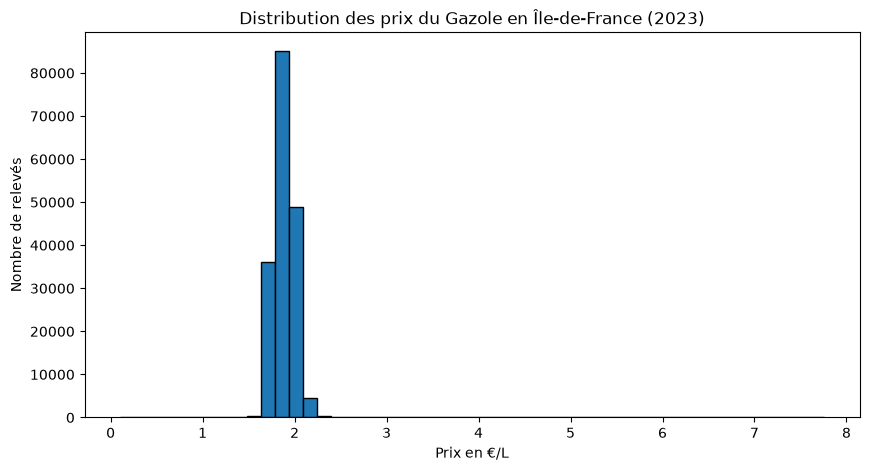

In [9]:
# Importation de l'outil pour faire des graphiques
import matplotlib.pyplot as plt

# Création de l'histogramme des prix avec 50 barres (bins)
df_2023['prix'].plot(kind='hist', bins=50, edgecolor='black', figsize=(10, 5))

# Ajout des titres
plt.title("Distribution des prix du Gazole en Île-de-France (2023)")
plt.xlabel("Prix en €/L")
plt.ylabel("Nombre de relevés")
plt.show()

In [10]:
# Calcul des quartiles (25% et 75%) et de l'écart interquartile (IQR)
Q1 = df_2023['prix'].quantile(0.25)
Q3 = df_2023['prix'].quantile(0.75)
IQR = Q3 - Q1

# Définition des limites mathématiques "normales" (règle des 1,5 x IQR)
limite_basse = Q1 - 1.5 * IQR
limite_haute = Q3 + 1.5 * IQR

# Création d'un sous-tableau contenant uniquement les prix hors limites
anomalies_prix = df_2023[(df_2023['prix'] < limite_basse) | (df_2023['prix'] > limite_haute)]

print(f"Limites normales calculées : de {limite_basse:.2f} € à {limite_haute:.2f} €")
print(f"Nombre de relevés de prix aberrants détectés : {len(anomalies_prix)}")

Limites normales calculées : de 1.56 € à 2.19 €
Nombre de relevés de prix aberrants détectés : 680


In [ ]:
# Affichage des 5 prix aberrants les plus BAS
print("--- PRIX ANORMALEMENT BAS ---")
display(anomalies_prix.sort_values('prix').head())

# Affichage des 5 prix aberrants les plus HAUTS
print("\n--- PRIX ANORMALEMENT HAUTS ---")
display(anomalies_prix.sort_values('prix', ascending=False).head())

--- PRIX ANORMALEMENT BAS ---


,id_pdv,cp,ville,carburant,date,prix
113584,92400016,92400,COURBEVOIE,Gazole,2023-04-02T15:33:29,0.100
113579,92400016,92400,COURBEVOIE,Gazole,2023-03-31T15:01:55,0.190
169141,95470004,95470,VEMARS,Gazole,2023-07-17T14:59:51,0.688
94249,91510002,91510,Lardy,Gazole,2023-12-18T09:15:17,0.699
59514,78360002,78360,MONTESSON,Gazole,2023-07-31T07:38:31,0.776



--- PRIX ANORMALEMENT HAUTS ---


,id_pdv,cp,ville,carburant,date,prix
144663,94380003,94380,BONNEUIL SUR MARNE,Gazole,2023-11-28T13:48:55,7.760
144677,94380003,94380,BONNEUIL SUR MARNE,Gazole,2023-12-15T09:42:08,7.719
109377,92230008,92230,GENNEVILLIERS,Gazole,2023-12-08T06:31:50,4.819
23636,77176001,77176,SAVIGNY-LE-TEMPLE,Gazole,2023-02-09T07:22:13,2.954
169073,95470004,95470,VEMARS,Gazole,2023-04-21T14:09:29,2.924


: 